# Прогноз конфликтной активности в Израиле

Сравниваю два baseline, ARIMA(1,1,0) и XGBoost. Прогнозирую количество записей GDELT на 1-4 недели вперёд.

In [1]:
import json
import os

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from xgboost import XGBRegressor

## 1. Данные

Загружаю таблицу признаков и полный недельный ряд. Сортирую по дате.

In [2]:
dataset = pd.read_csv(
    "../data/processed/israel_model_dataset.csv",
    parse_dates=["week_start"],
)
dataset = dataset.sort_values("week_start").reset_index(drop=True)

weekly = pd.read_csv(
    "../data/processed/israel_weekly_merged.csv",
    parse_dates=["week_start"],
)
weekly = weekly.sort_values("week_start").reset_index(drop=True)

print("Модельная таблица:", dataset.shape)
print("Полный недельный ряд:", weekly.shape)

Модельная таблица: (145, 37)
Полный недельный ряд: (157, 24)


Holdout начинается 13.07.2026 и занимает последние 12 недель. Ниже задаю исходные параметры XGBoost.

In [3]:
holdout_start = pd.Timestamp("2026-07-13")

xgb_params = {
    'n_estimators': 100,
    'max_depth': 2,
    'learning_rate': 0.05,
    'min_child_weight': 5,
    'reg_lambda': 10,
    'objective': 'reg:squarederror',
    'tree_method': 'hist',
    'random_state': 42,
    'n_jobs': 2,
}

## 2. Функции

### Метрики

Одна функция для MASE, sMAPE и RMSE. Масштаб MASE считаю по истории до первого прогноза на выбранном отрезке.

In [4]:
def calculate_metrics(actual, predicted, mase_scale):
    errors = actual - predicted
    mae = errors.abs().mean()
    mase = mae / mase_scale
    rmse = (errors ** 2).mean() ** 0.5
    denominator = actual.abs() + predicted.abs()
    denominator = denominator.replace(0, float("nan"))
    smape = (200 * errors.abs() / denominator).fillna(0).mean()
    return {"MASE": mase, "sMAPE": smape, "RMSE": rmse}


### Оценка моделей

Функция возвращает прогнозы и метрики на выбранных неделях. В обучение беру только известные к моменту прогноза ответы до holdout. Дату и таргеты исключаю из признаков.

Для каждого горизонта у XGBoost своя модель. ARIMA обновляет состояние уже прошедшими наблюдениями holdout без переоценки коэффициентов.

In [5]:
def evaluate_models(dataset, weekly, horizon, evaluation_weeks,
                    holdout_start, xgb_params, models_to_evaluate=None):
    if models_to_evaluate is None:
        models_to_evaluate = [
            "last_week", "rolling_mean_4", "arima_110", "xgboost"
        ]

    target_column = f"target_h{horizon}"
    target_columns = ["target_h1", "target_h2", "target_h3", "target_h4"]
    feature_columns = dataset.drop(
        columns=["week_start"] + target_columns
    ).columns.tolist()

    data = dataset.dropna(subset=[target_column]).copy()
    data["target_week"] = data["week_start"] + pd.Timedelta(weeks=horizon)
    test = data.loc[data["target_week"].isin(evaluation_weeks)].copy()

    series = weekly.set_index("week_start")["conflict_count_week"]
    series = series.asfreq("W-MON")
    first_origin = test["week_start"].min()
    mase_scale = series.loc[:first_origin].diff().abs().mean()

    predictions = test[["week_start", "target_week", target_column]].copy()
    predictions = predictions.rename(columns={
        "week_start": "origin_week",
        target_column: "actual",
    })

    if "last_week" in models_to_evaluate:
        predictions["last_week"] = test["conflict_count_week"]
    if "rolling_mean_4" in models_to_evaluate:
        predictions["rolling_mean_4"] = test["conflict_mean_4"]

    arima_predictions = []
    xgb_predictions = []

    for row_index in test.index:
        origin_week = test.loc[row_index, "week_start"]
        known_rows = data.loc[
            (data["week_start"] < origin_week)
            & (data["target_week"] <= origin_week)
            & (data["target_week"] < holdout_start)
        ]

        if "arima_110" in models_to_evaluate:
            history = series.loc[:origin_week]
            arima_train = history.loc[history.index < holdout_start]
            arima_model = ARIMA(arima_train, order=(1, 1, 0)).fit()

            observed_holdout = history.loc[history.index >= holdout_start]
            if not observed_holdout.empty:
                arima_model = arima_model.append(observed_holdout, refit=False)

            arima_forecast = arima_model.forecast(steps=horizon)
            arima_predictions.append(max(0, float(arima_forecast.iloc[-1])))

        if "xgboost" in models_to_evaluate:
            X_train = known_rows[feature_columns]
            y_train = known_rows[target_column]
            X_predict = test.loc[[row_index], feature_columns]

            boosting_model = XGBRegressor(**xgb_params)
            boosting_model.fit(X_train, y_train)
            xgb_forecast = float(boosting_model.predict(X_predict)[0])
            xgb_predictions.append(max(0, xgb_forecast))

    if "arima_110" in models_to_evaluate:
        predictions["arima_110"] = arima_predictions
    if "xgboost" in models_to_evaluate:
        predictions["xgboost"] = xgb_predictions
    predictions["horizon"] = horizon

    results = []
    for model_name in models_to_evaluate:
        scores = calculate_metrics(
            predictions["actual"], predictions[model_name], mase_scale
        )
        scores["model"] = model_name
        scores["horizon"] = horizon
        results.append(scores)

    metrics = pd.DataFrame(
        results, columns=["model", "horizon", "MASE", "sMAPE", "RMSE"]
    )
    return predictions, metrics

## 3. Проверка на development

Три отрезка по 12 недель, на каждом проверяю h1-h4. CV заканчивается 15.06.2026, чтобы подбор был завершён к первому прогнозу holdout на h4.

In [6]:
max_horizon = 4

selection_cutoff = holdout_start - pd.Timedelta(weeks=max_horizon)

selection_weeks = weekly.loc[
    weekly["week_start"] <= selection_cutoff, "week_start"
].sort_values()

cv_weeks = selection_weeks.tail(36).tolist()

folds = []
for start in [0, 12, 24]:
    folds.append(cv_weeks[start:start + 12])

print("Последняя целевая неделя для подбора:", selection_cutoff.date())
for fold_number, weeks in enumerate(folds, start=1):
    print(fold_number, weeks[0].date(), weeks[-1].date(), len(weeks))

Последняя целевая неделя для подбора: 2026-06-15
1 2025-10-13 2025-12-29 12
2 2026-01-05 2026-03-23 12
3 2026-03-30 2026-06-15 12


### Исходные модели

Считаю прогнозы для всех отрезков и горизонтов с исходными параметрами.

In [7]:
prediction_tables = []
metric_tables = []
for fold_number, validation_weeks in enumerate(folds, start=1):
    for cv_horizon in [1, 2, 3, 4]:
        print("Отрезок:", fold_number, "Горизонт:", cv_horizon)
        fold_predictions, fold_metrics = evaluate_models(
            dataset, weekly, cv_horizon, validation_weeks,
            holdout_start, xgb_params
        )
        fold_predictions["fold"] = fold_number
        fold_metrics["fold"] = fold_number
        prediction_tables.append(fold_predictions)
        metric_tables.append(fold_metrics)
all_predictions = pd.concat(prediction_tables, ignore_index=True)
all_metrics = pd.concat(metric_tables, ignore_index=True)
print("Прогнозы:", all_predictions.shape)
print("Метрики:", all_metrics.shape)


Отрезок: 1 Горизонт: 1
Отрезок: 1 Горизонт: 2
Отрезок: 1 Горизонт: 3
Отрезок: 1 Горизонт: 4
Отрезок: 2 Горизонт: 1
Отрезок: 2 Горизонт: 2
Отрезок: 2 Горизонт: 3
Отрезок: 2 Горизонт: 4
Отрезок: 3 Горизонт: 1
Отрезок: 3 Горизонт: 2
Отрезок: 3 Горизонт: 3
Отрезок: 3 Горизонт: 4
Прогнозы: (144, 9)
Метрики: (48, 6)


### Метрики CV

Сначала результаты каждого отрезка, затем среднее по трём отрезкам для каждого горизонта. RMSE тоже усредняется по отрезкам.

In [8]:
display(all_metrics.round(3))


,model,horizon,MASE,sMAPE,RMSE,fold
0,last_week,1,0.309,11.550,1145.568,1
1,rolling_mean_4,1,0.435,15.928,1371.793,1
2,arima_110,1,0.325,12.069,1162.853,1
3,xgboost,1,0.818,29.144,2306.738,1
4,last_week,2,0.449,15.743,1568.080,1
5,rolling_mean_4,2,0.544,19.876,1688.632,1
6,arima_110,2,0.469,16.445,1607.537,1
7,xgboost,2,0.947,32.943,2910.803,1
8,last_week,3,0.515,18.289,1672.595,1
9,rolling_mean_4,3,0.689,24.691,2039.729,1


In [9]:
summary = (
    all_metrics.groupby(["horizon", "model"])[["MASE", "sMAPE", "RMSE"]]
    .mean()
    .reset_index()
)
display(summary.round(3))


,horizon,model,MASE,sMAPE,RMSE
0,1,arima_110,0.586,15.998,2163.646
1,1,last_week,0.560,15.379,2141.439
2,1,rolling_mean_4,0.777,21.308,2825.166
3,1,xgboost,0.847,25.752,2758.655
4,2,arima_110,0.799,21.705,2998.148
5,2,last_week,0.792,21.482,2966.203
6,2,rolling_mean_4,0.960,26.396,3427.763
7,2,xgboost,1.244,35.631,3843.025
8,3,arima_110,0.964,25.859,3495.355
9,3,last_week,0.969,26.046,3489.024


## 4. Подбор XGBoost

Проверяю 36 конфигураций. Выбираю общие параметры для h1-h4 по среднему MASE на CV. Holdout в подборе не участвует.

In [ ]:
search_candidates = []

for max_depth in [2, 4, 6]:
    for learning_rate in [0.02, 0.05, 0.1]:
        for n_estimators in [100, 400]:
            for reg_lambda in [1, 10]:
                candidate = xgb_params.copy()
                candidate["max_depth"] = max_depth
                candidate["learning_rate"] = learning_rate
                candidate["n_estimators"] = n_estimators
                candidate["reg_lambda"] = reg_lambda
                search_candidates.append(candidate)

print("Число конфигураций:", len(search_candidates))
display(pd.DataFrame(search_candidates)[[
    "max_depth", "learning_rate", "n_estimators", "reg_lambda"
]])


Число конфигураций: 36


,max_depth,learning_rate,n_estimators,reg_lambda
0,2,0.02,100,1
1,2,0.02,100,10
2,2,0.02,400,1
3,2,0.02,400,10
4,2,0.05,100,1
5,2,0.05,100,10
6,2,0.05,400,1
7,2,0.05,400,10
8,2,0.10,100,1
9,2,0.10,100,10


: 

### Перебор параметров

Для каждой конфигурации запускаю только XGBoost. Это самая долгая часть: 5184 обучения.

In [ ]:
search_rows = []
tuning_metric_tables = []
tuning_prediction_tables = []

for trial_number, candidate in enumerate(search_candidates, start=1):
    print("Конфигурация:", trial_number, "/", len(search_candidates))
    print(
        "depth:", candidate["max_depth"],
        "lr:", candidate["learning_rate"],
        "trees:", candidate["n_estimators"],
        "lambda:", candidate["reg_lambda"],
    )

    trial_metric_tables = []
    trial_prediction_tables = []

    for fold_number, validation_weeks in enumerate(folds, start=1):
        for cv_horizon in [1, 2, 3, 4]:
            trial_predictions, trial_metrics = evaluate_models(
                dataset, weekly, cv_horizon, validation_weeks,
                holdout_start, candidate,
                models_to_evaluate=["xgboost"],
            )
            trial_predictions["fold"] = fold_number
            trial_metrics["fold"] = fold_number
            trial_prediction_tables.append(trial_predictions)
            trial_metric_tables.append(trial_metrics)

    trial_metrics = pd.concat(trial_metric_tables, ignore_index=True)
    trial_predictions = pd.concat(trial_prediction_tables, ignore_index=True)
    trial_metrics["trial"] = trial_number
    trial_predictions["trial"] = trial_number

    tuning_metric_tables.append(trial_metrics)
    tuning_prediction_tables.append(trial_predictions)

    search_rows.append({
        "trial": trial_number,
        "max_depth": candidate["max_depth"],
        "learning_rate": candidate["learning_rate"],
        "n_estimators": candidate["n_estimators"],
        "reg_lambda": candidate["reg_lambda"],
        "mean_MASE": trial_metrics["MASE"].mean(),
        "mean_sMAPE": trial_metrics["sMAPE"].mean(),
        "mean_RMSE": trial_metrics["RMSE"].mean(),
    })

tuning_results = (
    pd.DataFrame(search_rows)
    .sort_values("mean_MASE", kind="stable")
    .reset_index(drop=True)
)
tuning_metrics = pd.concat(tuning_metric_tables, ignore_index=True)
tuning_predictions = pd.concat(tuning_prediction_tables, ignore_index=True)

display(tuning_results.head(10).round(4))


Конфигурация: 1 / 36
depth: 2 lr: 0.02 trees: 100 lambda: 1
Конфигурация: 2 / 36
depth: 2 lr: 0.02 trees: 100 lambda: 10
Конфигурация: 3 / 36
depth: 2 lr: 0.02 trees: 400 lambda: 1
Конфигурация: 4 / 36
depth: 2 lr: 0.02 trees: 400 lambda: 10
Конфигурация: 5 / 36
depth: 2 lr: 0.05 trees: 100 lambda: 1
Конфигурация: 6 / 36
depth: 2 lr: 0.05 trees: 100 lambda: 10
Конфигурация: 7 / 36
depth: 2 lr: 0.05 trees: 400 lambda: 1
Конфигурация: 8 / 36
depth: 2 lr: 0.05 trees: 400 lambda: 10
Конфигурация: 9 / 36
depth: 2 lr: 0.1 trees: 100 lambda: 1
Конфигурация: 10 / 36
depth: 2 lr: 0.1 trees: 100 lambda: 10
Конфигурация: 11 / 36
depth: 2 lr: 0.1 trees: 400 lambda: 1
Конфигурация: 12 / 36
depth: 2 lr: 0.1 trees: 400 lambda: 10
Конфигурация: 13 / 36
depth: 4 lr: 0.02 trees: 100 lambda: 1
Конфигурация: 14 / 36
depth: 4 lr: 0.02 trees: 100 lambda: 10
Конфигурация: 15 / 36
depth: 4 lr: 0.02 trees: 400 lambda: 1
Конфигурация: 16 / 36
depth: 4 lr: 0.02 trees: 400 lambda: 10
Конфигурация: 17 / 36
depth: 

### Лучшие параметры

Беру конфигурацию с минимальным средним MASE. Смотрю результат по горизонтам и сравниваю с исходными моделями.

In [ ]:
best_trial = int(tuning_results.loc[0, "trial"])
best_xgb_params = search_candidates[best_trial - 1].copy()

best_cv_metrics = tuning_metrics.loc[
    tuning_metrics["trial"] == best_trial
].copy()
best_cv_predictions = tuning_predictions.loc[
    tuning_predictions["trial"] == best_trial
].copy()

print("Лучшая конфигурация:", best_trial)
print(best_xgb_params)

best_by_horizon = (
    best_cv_metrics
    .groupby("horizon")[["MASE", "sMAPE", "RMSE"]]
    .mean()
    .reset_index()
)
display(best_by_horizon.round(3))

cv_comparison = (
    all_metrics.groupby("model")[["MASE", "sMAPE", "RMSE"]]
    .mean()
    .reset_index()
)
best_scores = {
    "model": "xgboost_tuned",
    "MASE": best_cv_metrics["MASE"].mean(),
    "sMAPE": best_cv_metrics["sMAPE"].mean(),
    "RMSE": best_cv_metrics["RMSE"].mean(),
}
cv_comparison = pd.concat(
    [cv_comparison, pd.DataFrame([best_scores])],
    ignore_index=True,
)
display(cv_comparison.sort_values("MASE").round(3))

display(best_cv_predictions[[
    "fold", "horizon", "origin_week", "target_week", "actual", "xgboost"
]].head(12))


Лучшая конфигурация: 27
{'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.02, 'min_child_weight': 5, 'reg_lambda': 1, 'objective': 'reg:squarederror', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': 2}


,horizon,MASE,sMAPE,RMSE
0,1,0.822,22.948,2918.938
1,2,1.171,33.180,3990.731
2,3,1.175,36.034,3906.049
3,4,1.519,44.859,4542.568


,model,MASE,sMAPE,RMSE
1,last_week,0.871,23.658,3188.321
0,arima_110,0.880,23.844,3215.861
2,rolling_mean_4,1.046,29.079,3640.647
4,xgboost_tuned,1.172,34.255,3839.571
3,xgboost,1.222,35.636,3781.639


,fold,horizon,origin_week,target_week,actual,xgboost
3744,1,1,2025-10-06,2025-10-13,10751.0,7861.448730
3745,1,1,2025-10-13,2025-10-20,7643.0,10687.767578
3746,1,1,2025-10-20,2025-10-27,7976.0,8591.217773
3747,1,1,2025-10-27,2025-11-03,7670.0,10484.756836
3748,1,1,2025-11-03,2025-11-10,6310.0,8867.580078
3749,1,1,2025-11-10,2025-11-17,7545.0,7813.823242
3750,1,1,2025-11-17,2025-11-24,7075.0,9493.624023
3751,1,1,2025-11-24,2025-12-01,6359.0,7868.534180
3752,1,1,2025-12-01,2025-12-08,5628.0,10060.385742
3753,1,1,2025-12-08,2025-12-15,5431.0,7220.213867


## 5. Holdout

Последние 12 недель. Параметры уже выбраны на CV. Ответы holdout не входят в обучение, но завершившиеся недели доступны для текущих признаков.

In [ ]:
holdout_weeks = weekly["week_start"].tail(12).tolist()

print("Holdout:", holdout_weeks[0].date(), "—", holdout_weeks[-1].date())

Holdout: 2026-07-13 — 2026-09-28


### Прогнозы и метрики

Проверяю все модели на h1-h4. Получаю 48 строк прогнозов и 16 строк метрик.

In [ ]:
holdout_prediction_tables = []
holdout_metric_tables = []

for final_horizon in [1, 2, 3, 4]:
    print("Holdout, горизонт:", final_horizon)

    horizon_predictions, horizon_metrics = evaluate_models(
        dataset, weekly, final_horizon, holdout_weeks,
        holdout_start, best_xgb_params,
    )

    holdout_prediction_tables.append(horizon_predictions)
    holdout_metric_tables.append(horizon_metrics)

holdout_predictions = pd.concat(holdout_prediction_tables, ignore_index=True)
holdout_metrics = pd.concat(holdout_metric_tables, ignore_index=True)

display(holdout_metrics.round(3))
display(holdout_predictions.head(12))

Holdout, горизонт: 1
Holdout, горизонт: 2
Holdout, горизонт: 3
Holdout, горизонт: 4


,model,horizon,MASE,sMAPE,RMSE
0,last_week,1,0.350,14.225,1017.214
1,rolling_mean_4,1,0.314,13.011,868.851
2,arima_110,1,0.353,14.266,1048.750
3,xgboost,1,0.523,19.586,1595.963
4,last_week,2,0.425,17.494,1149.875
5,rolling_mean_4,2,0.349,14.378,977.479
6,arima_110,2,0.432,17.732,1196.134
7,xgboost,2,0.955,36.420,2615.326
8,last_week,3,0.389,16.040,1089.083
9,rolling_mean_4,3,0.304,12.195,1123.631


,origin_week,target_week,actual,last_week,rolling_mean_4,arima_110,xgboost,horizon
0,2026-07-06,2026-07-13,4718.0,5155,5688.00,5165.791479,4610.519043,1
1,2026-07-13,2026-07-20,6697.0,4718,5087.75,4681.157217,4512.925781,1
2,2026-07-20,2026-07-27,5826.0,6697,5399.25,6863.846379,5677.923340,1
3,2026-07-27,2026-08-03,5278.0,5826,5599.00,5752.567359,7460.593262,1
4,2026-08-03,2026-08-10,5181.0,5278,5629.75,5231.798981,5291.669434,1
5,2026-08-10,2026-08-17,7103.0,5181,5745.50,5172.822082,5200.140625,1
6,2026-08-17,2026-08-24,5664.0,7103,5847.00,7265.040799,7934.660156,1
7,2026-08-24,2026-08-31,5279.0,5664,5806.50,5542.680172,5804.743164,1
8,2026-08-31,2026-09-07,5094.0,5279,5806.75,5246.541255,5159.717285,1
9,2026-09-07,2026-09-14,4607.0,5094,5785.00,5078.402941,6788.917969,1


### Сравнение с last_week

Положительный MASE_improvement_pct означает снижение ошибки относительно last_week, отрицательный - проигрыш.

In [ ]:
baseline_scores = holdout_metrics.loc[
    holdout_metrics["model"] == "last_week", ["horizon", "MASE"]
].copy()
baseline_scores = baseline_scores.rename(columns={"MASE": "baseline_MASE"})

holdout_comparison = holdout_metrics.merge(baseline_scores, on="horizon")
holdout_comparison["MASE_improvement_pct"] = (
    100 * (1 - holdout_comparison["MASE"] / holdout_comparison["baseline_MASE"])
)

display(holdout_comparison.round(3))

,model,horizon,MASE,sMAPE,RMSE,baseline_MASE,MASE_improvement_pct
0,last_week,1,0.350,14.225,1017.214,0.350,0.000
1,rolling_mean_4,1,0.314,13.011,868.851,0.350,10.331
2,arima_110,1,0.353,14.266,1048.750,0.350,-0.882
3,xgboost,1,0.523,19.586,1595.963,0.350,-49.481
4,last_week,2,0.425,17.494,1149.875,0.425,0.000
5,rolling_mean_4,2,0.349,14.378,977.479,0.425,17.769
6,arima_110,2,0.432,17.732,1196.134,0.425,-1.843
7,xgboost,2,0.955,36.420,2615.326,0.425,-124.878
8,last_week,3,0.389,16.040,1089.083,0.389,0.000
9,rolling_mean_4,3,0.304,12.195,1123.631,0.389,21.770


### Графики

Факт и прогнозы по каждому горизонту. Сохраняю в outputs/figures.

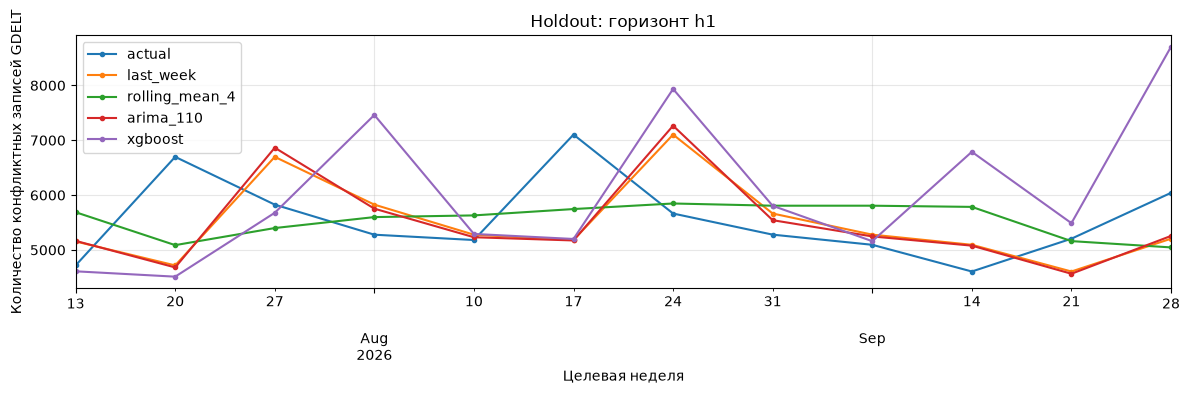

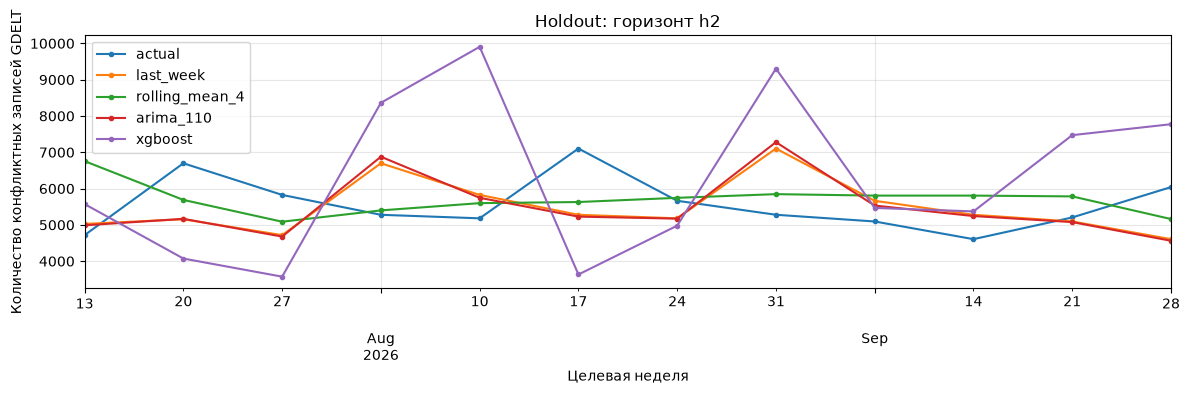

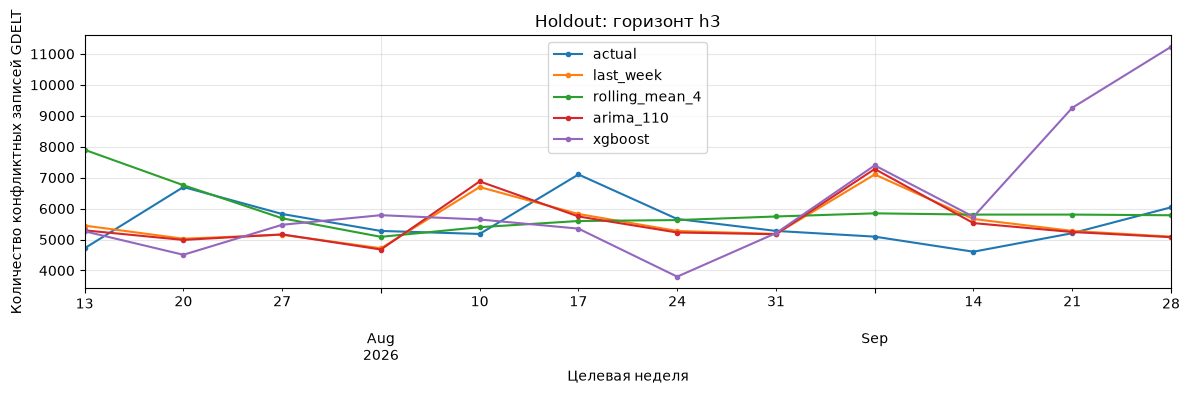

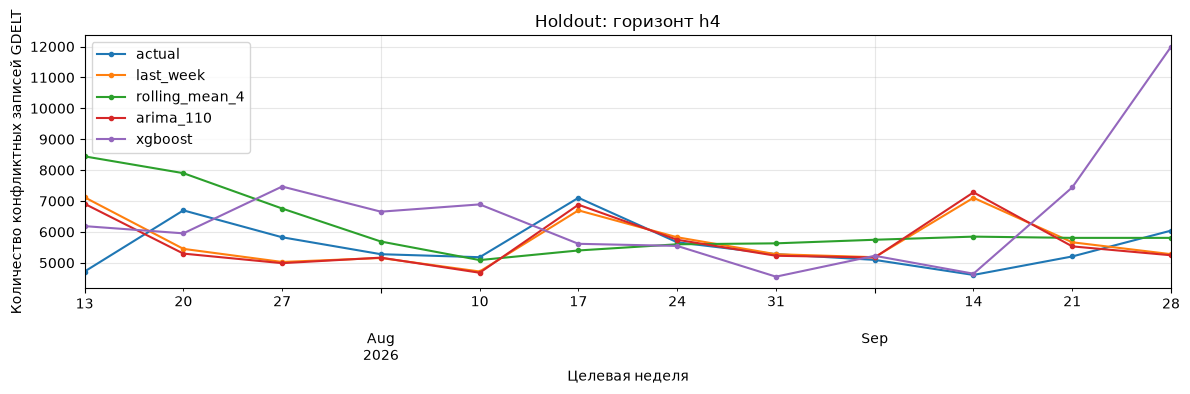

In [ ]:
os.makedirs("../outputs/figures", exist_ok=True)

for final_horizon in [1, 2, 3, 4]:
    plot_data = holdout_predictions.loc[
        holdout_predictions["horizon"] == final_horizon
    ]
    plot_data = plot_data.set_index("target_week")

    plot_data[[
        "actual", "last_week", "rolling_mean_4", "arima_110", "xgboost",
    ]].plot(figsize=(12, 4), marker="o", markersize=3)

    plt.title(f"Holdout: горизонт h{final_horizon}")
    plt.xlabel("Целевая неделя")
    plt.ylabel("Количество конфликтных записей GDELT")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"../outputs/figures/holdout_h{final_horizon}.png", dpi=150)
    plt.show()
    plt.close()

### Сохранение метрик

Итоговые метрики и сравнение с baseline сохраняю в outputs/metrics.json. Промежуточные таблицы остаются в памяти.

In [ ]:
metrics_report = {
    "country": "Israel",
    "target_type": "regression",
    "holdout_start": holdout_start.strftime("%Y-%m-%d"),
    "holdout_end": holdout_weeks[-1].strftime("%Y-%m-%d"),
    "protocol": "weekly forecasts; development training only; past holdout updates ARIMA state without refit",
    "selection_cutoff": selection_cutoff.strftime("%Y-%m-%d"),
    "metrics": holdout_comparison.to_dict(orient="records"),
}

with open("../outputs/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics_report, file, ensure_ascii=False, indent=2, allow_nan=False)

## Прогноз на следующие четыре недели

Использую last_week: у него лучший средний MASE на CV. Интервалы оцениваю по ошибкам CV отдельно для каждого горизонта. Сохраняю прогноз в outputs/forecast.csv.

In [ ]:
last_week = weekly["week_start"].iloc[-1]
last_count = float(weekly["conflict_count_week"].iloc[-1])
forecast_rows = []

for horizon in [1, 2, 3, 4]:
    cv = all_predictions.loc[all_predictions["horizon"] == horizon]
    errors = cv["actual"] - cv["last_week"]

    forecast_rows.append({
        "country": "Israel",
        "forecast_week": last_week + pd.Timedelta(weeks=horizon),
        "horizon": horizon,
        "target_type": "count",
        "predicted_value": last_count,
        "predicted_prob": None,
        "ci_lower": max(0, last_count + errors.quantile(0.025)),
        "ci_upper": max(0, last_count + errors.quantile(0.975)),
        "model": "last_week",
    })

forecast = pd.DataFrame(forecast_rows)
os.makedirs("../outputs", exist_ok=True)
forecast.to_csv("../outputs/forecast.csv", index=False, date_format="%Y-%m-%d")
display(forecast)

,country,forecast_week,horizon,target_type,predicted_value,predicted_prob,ci_lower,ci_upper,model
0,Israel,2026-10-05,1,count,6041.0,None,1750.50,12032.875,last_week
1,Israel,2026-10-12,2,count,6041.0,None,1806.50,13156.875,last_week
2,Israel,2026-10-19,3,count,6041.0,None,295.75,15932.625,last_week
3,Israel,2026-10-26,4,count,6041.0,None,0.00,16361.500,last_week
